In [1]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
import os
from PIL import Image
from scipy.sparse import hstack
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, ConfusionMatrixDisplay
from torchvision import models, transforms

DATA = 'C:/Users/Admin/Downloads/retail-products-classification/'                                        
TEXT, IMG, LABEL = 'text', 'path', 'categories'

df = pd.read_csv(DATA + 'train.csv').dropna(subset=['title', LABEL])
df['description'] = df['description'].fillna('')
df[TEXT] = df['title'] + ' ' + df['description']

files = {os.path.splitext(f)[0]: os.path.relpath(os.path.join(r, f), DATA)
         for r, _, fs in os.walk(DATA) for f in fs if f.lower().endswith(('.jpg', '.jpeg'))}
df[IMG] = df['ImgId'].map(files)
df = df.dropna(subset=[IMG]).sample(1500, random_state=0).reset_index(drop=True)
print(len(files), 'photo found |', df.shape)

48367 photo found | (1500, 6)


(1500, 6) | категорій: 21
categories
All Beauty                   86
Arts, Crafts & Sewing        83
Musical Instruments          83
Sports & Outdoors            81
Cell Phones & Accessories    77
Name: count, dtype: int64
New Fashion Korean Style Women Black Devil Skull Pattern Pu Leather Tote Bag Shipping Bag Material: High Quality PU Leather (PU is not the real leather, it is manmade)

All Accessories not Included

NOTE: The actual item's color maybe slightly different from the pictures shown due to the lighting or computer screens.

Package:

1 x Handbag -> All Beauty
Bushnell .22 Rimfire 4x32 Riflescope (Black) Bushnell .22 rimfire scopes are designed specifically for .22 rimfire rifles. Features 50-yard parallax setting. Includes rings, fully coated optics for low-light shooting and easy-grip power change ring. One-piece 1" tube is waterproof and fogproof. 1/4 M.O.A. fingertip windage and elevation adjustments.

- Features: Multi-X Reticle, Fully coated optics, Includes free ring

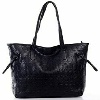

In [2]:
print(df.shape, '| категорій:', df[LABEL].nunique())
print(df[LABEL].value_counts().head())
for i in range(3): print(df[TEXT][i], '->', df[LABEL][i])
Image.open(DATA + df[IMG][0])

In [6]:
tr, va = train_test_split(np.arange(len(df)), test_size=0.2, random_state=0)
y = df[LABEL].values

tfidf = TfidfVectorizer(max_features=20000)
T = tfidf.fit_transform(df[TEXT])      

cnn = models.resnet18(weights='DEFAULT'); cnn.fc = torch.nn.Identity(); cnn.eval()
tf = transforms.Compose([transforms.Resize((128, 128)), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
with torch.no_grad():
    F = np.vstack([cnn(tf(Image.open(DATA + p).convert('RGB'))[None]).numpy() for p in df[IMG]])

def fit_predict(X):
    X = X.tocsr() if hasattr(X, 'tocsr') else X
    return LogisticRegression(max_iter=1000).fit(X[tr], y[tr]).predict(X[va])

preds = {'Text': fit_predict(T), 'Photo': fit_predict(F), 'Text+Photo': fit_predict(hstack([T, F]))}

Text         acc=0.543  prec=0.647  rec=0.528  f1=0.515
Photo        acc=0.260  prec=0.279  rec=0.255  f1=0.260
Text+Photo   acc=0.257  prec=0.276  rec=0.251  f1=0.257


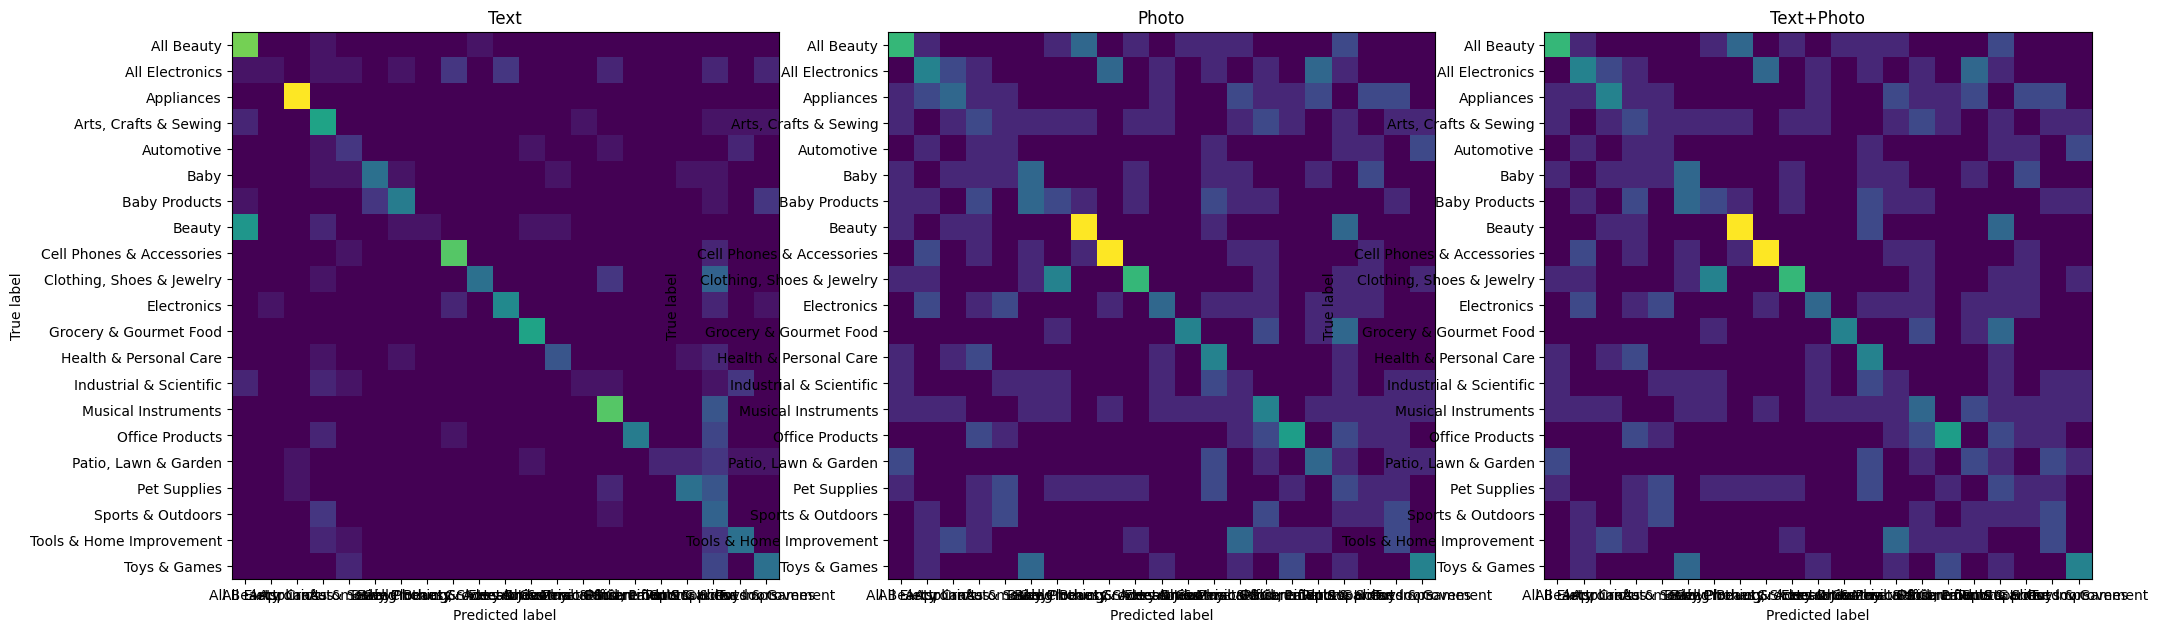

In [8]:
for n, p in preds.items():
    pr, rc, f1, _ = precision_recall_fscore_support(y[va], p, average='macro', zero_division=0)
    print(f'{n:12} acc={accuracy_score(y[va], p):.3f}  prec={pr:.3f}  rec={rc:.3f}  f1={f1:.3f}')

fig, ax = plt.subplots(1, 3, figsize=(24, 8))
for a, (n, p) in zip(ax, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y[va], p, ax=a, include_values=False, colorbar=False); a.set_title(n)
plt.show()

In [9]:
pt, pi, yv = preds['Text'], preds['Photo'], y[va]
for mask, name in [((pt != yv) & (pi == yv), 'Text mistake, photo no'),
                   ((pt == yv) & (pi != yv), 'Photo mistake, text no')]:
    print('\n' + name, '| All:', mask.sum())
    for i in np.where(mask)[0][:5]:
        print(df[TEXT][va[i]][:60], '| True:', yv[i], '| Text:', pt[i], '| Photo:', pi[i])


Text mistake, photo no | All: 32
Maybelline New York Volum' Express Washable Mascara, Very Bl | True: Beauty | Text: All Beauty | Photo: Beauty
Dr. Bronner Peppermint 18-in-1 Pure-Castile Soap - 32 Fluid  | True: Beauty | Text: Health & Personal Care | Photo: Beauty
Liquid Tooth Blackout Our Liquid Tooth Blackout is great for | True: Clothing, Shoes & Jewelry | Text: Arts, Crafts & Sewing | Photo: Clothing, Shoes & Jewelry
Martin SCX-700 DMX Color Scanner (CDM-150) Flat Mirror Scann | True: All Electronics | Text: Sports & Outdoors | Photo: All Electronics
Garmin Suction Cup Mount including speaker w/12V cable (iQue | True: Cell Phones & Accessories | Text: Sports & Outdoors | Photo: Cell Phones & Accessories

Photo mistake, text no | All: 117
GE WR55X10956 Main Control Board Assembly for Refrigerator G | True: Appliances | Text: Appliances | Photo: Tools & Home Improvement
equinux TubeStick Hybrid ATSC TubeStick hybrid is a TV recei | True: All Electronics | Text: All Electronics | P